# Intelligent Taxi Routing — Q-Learning on Taxi-v3

This notebook walks through the full reinforcement-learning pipeline used in this project,
cell by cell: environment inspection, tabular Q-learning, training, evaluation, a random-policy
baseline, and failure analysis. It mirrors the logic in `src/`, written inline here so every
step is visible and easy to explain.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym

np.random.seed(42)
plt.style.use("dark_background")

## 2. Environment Creation

Taxi-v3 is a discrete, fully-observable gridworld from Gymnasium's "Toy Text" suite.
The taxi must pick up a passenger at one of four marked locations and drop them off at another.

In [2]:
env = gym.make("Taxi-v3")
state, info = env.reset(seed=42)
print("Initial state id:", state)
print("Info:", info)

Initial state id: 386
Info: {'prob': 1.0, 'action_mask': array([1, 1, 0, 1, 0, 0], dtype=int8)}


## 3. Environment Inspection

Let's render the grid as text and decode the state into its human-readable components.

In [3]:
print(env.render() if env.render_mode else "(set render_mode='ansi' to see text rendering)")

# Decode the integer state into (taxi_row, taxi_col, passenger_idx, destination_idx)
taxi_row, taxi_col, passenger_idx, destination_idx = env.unwrapped.decode(state)
print(f"taxi_row={taxi_row}, taxi_col={taxi_col}, passenger_idx={passenger_idx}, destination_idx={destination_idx}")

(set render_mode='ansi' to see text rendering)
taxi_row=3, taxi_col=4, passenger_idx=1, destination_idx=2


## 4. State and Action Spaces

- **State space**: `Discrete(500)` = 5 (taxi row) x 5 (taxi col) x 5 (passenger: R/G/Y/B/in-taxi) x 4 (destination: R/G/Y/B)
- **Action space**: `Discrete(6)` = South, North, East, West, Pickup, Drop-off

In [4]:
n_states = env.observation_space.n
n_actions = env.action_space.n
print("Number of states:", n_states)
print("Number of actions:", n_actions)

ACTION_NAMES = {0: "South", 1: "North", 2: "East", 3: "West", 4: "Pickup", 5: "Drop-off"}
ACTION_NAMES

Number of states: 500
Number of actions: 6


{0: 'South', 1: 'North', 2: 'East', 3: 'West', 4: 'Pickup', 5: 'Drop-off'}

## 5. Q-Table Initialization

The Q-table is a lookup table of shape `(n_states, n_actions)`. Each entry `Q[s, a]` holds the
agent's current estimate of the expected total future reward for taking action `a` in state `s`.
We start with all zeros — the agent knows nothing yet.

In [5]:
q_table = np.zeros((n_states, n_actions))
q_table.shape

(500, 6)

## 6. Hyperparameters

In [6]:
learning_rate = 0.1       # alpha: how much new info overrides old estimates
discount_factor = 0.95    # gamma: how much future reward matters vs. immediate reward
epsilon = 1.0              # initial exploration rate
epsilon_decay = 0.995      # multiplicative decay applied after every episode
epsilon_min = 0.01         # floor for epsilon so the agent never stops exploring completely
episodes = 10000
max_steps = 200

## 7. Q-Learning Update Function

The core of the algorithm — the Bellman equation:

```
Q(s, a) <- Q(s, a) + alpha * [ r + gamma * max_a' Q(s', a') - Q(s, a) ]
```

`max_a' Q(s', a')` is the best value achievable from the next state. Using this "bootstrapped"
estimate (rather than waiting for the episode to end) is what makes Q-learning efficient.

In [7]:
def q_learning_update(q_table, state, action, reward, next_state, done, alpha, gamma):
    best_next_value = 0.0 if done else np.max(q_table[next_state])
    td_target = reward + gamma * best_next_value
    td_error = td_target - q_table[state, action]
    q_table[state, action] += alpha * td_error
    return td_error

## 8. Epsilon-Greedy Action Selection

With probability `epsilon`, explore (random action). Otherwise, exploit (best known action).
This balances discovering new information against using what's already been learned.

In [8]:
def epsilon_greedy_action(q_table, state, epsilon, n_actions):
    if np.random.random() < epsilon:
        return np.random.randint(n_actions)          # explore
    return int(np.argmax(q_table[state]))              # exploit

## 9. Training Loop

Run the agent through `episodes` full pickup-and-dropoff attempts, updating the Q-table after
every single step, and decaying epsilon after every episode.

In [9]:
episode_rewards = []
episode_steps = []
epsilon_history = []

for episode in range(episodes):
    state, _ = env.reset(seed=None)
    total_reward = 0.0
    steps = 0

    for _ in range(max_steps):
        action = epsilon_greedy_action(q_table, state, epsilon, n_actions)
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        q_learning_update(q_table, state, action, reward, next_state, done, learning_rate, discount_factor)

        state = next_state
        total_reward += reward
        steps += 1
        if done:
            break

    epsilon = max(epsilon_min, epsilon * epsilon_decay)

    episode_rewards.append(total_reward)
    episode_steps.append(steps)
    epsilon_history.append(epsilon)

    if (episode + 1) % 2000 == 0:
        recent_avg = np.mean(episode_rewards[-100:])
        print(f"Episode {episode+1}/{episodes} | avg reward (last 100) = {recent_avg:.2f} | epsilon = {epsilon:.3f}")

print("Training complete.")

Episode 2000/10000 | avg reward (last 100) = 6.86 | epsilon = 0.010


Episode 4000/10000 | avg reward (last 100) = 7.03 | epsilon = 0.010


Episode 6000/10000 | avg reward (last 100) = 6.93 | epsilon = 0.010


Episode 8000/10000 | avg reward (last 100) = 7.35 | epsilon = 0.010


Episode 10000/10000 | avg reward (last 100) = 7.23 | epsilon = 0.010
Training complete.


## 10. Reward Progression

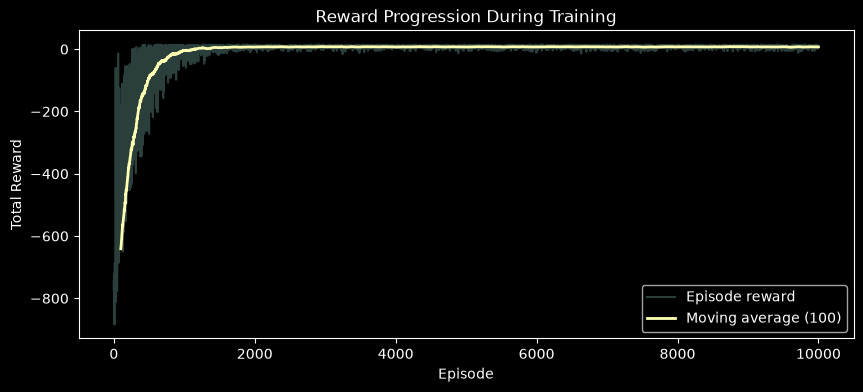

In [10]:
def moving_average(x, window=100):
    window = min(window, len(x))
    return np.convolve(x, np.ones(window) / window, mode="valid")

plt.figure(figsize=(10, 4))
plt.plot(episode_rewards, alpha=0.3, label="Episode reward")
plt.plot(range(99, len(episode_rewards)), moving_average(episode_rewards, 100), label="Moving average (100)", linewidth=2)
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("Reward Progression During Training")
plt.legend()
plt.show()

## 11. Steps per Episode

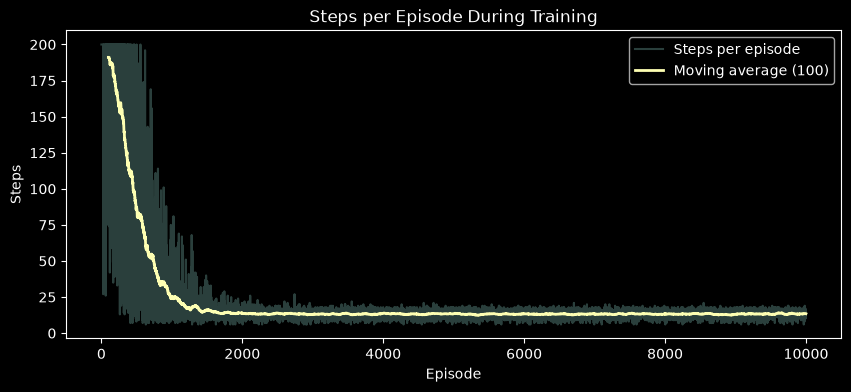

In [11]:
plt.figure(figsize=(10, 4))
plt.plot(episode_steps, alpha=0.3, label="Steps per episode")
plt.plot(range(99, len(episode_steps)), moving_average(episode_steps, 100), label="Moving average (100)", linewidth=2)
plt.xlabel("Episode")
plt.ylabel("Steps")
plt.title("Steps per Episode During Training")
plt.legend()
plt.show()

## 12. Epsilon Decay

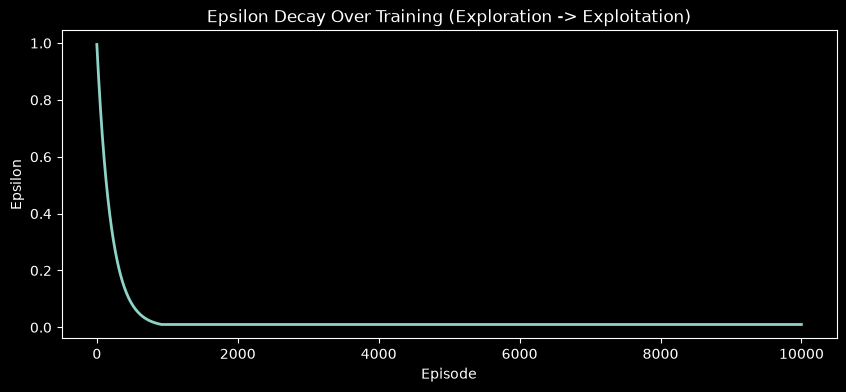

In [12]:
plt.figure(figsize=(10, 4))
plt.plot(epsilon_history, linewidth=2)
plt.xlabel("Episode")
plt.ylabel("Epsilon")
plt.title("Epsilon Decay Over Training (Exploration -> Exploitation)")
plt.show()

## 13. Evaluation

Evaluate the trained agent **greedily** (epsilon=0, always exploit) over 100 fresh episodes.

In [13]:
def evaluate(policy_fn, episodes=100, max_steps=200, seed=123):
    rewards, steps_list, successes = [], [], []
    for ep in range(episodes):
        state, _ = env.reset(seed=seed + ep)
        total_reward = 0.0
        steps = 0
        terminated = truncated = False
        for _ in range(max_steps):
            action = policy_fn(state)
            state, reward, terminated, truncated, _ = env.step(action)
            total_reward += reward
            steps += 1
            if terminated or truncated:
                break
        rewards.append(total_reward)
        steps_list.append(steps)
        successes.append(terminated and not truncated)
    return {
        "avg_reward": float(np.mean(rewards)),
        "std_reward": float(np.std(rewards)),
        "avg_steps": float(np.mean(steps_list)),
        "success_rate": float(np.mean(successes)),
        "rewards": rewards,
        "steps": steps_list,
        "successes": successes,
    }

q_policy = lambda s: int(np.argmax(q_table[s]))
q_eval = evaluate(q_policy, episodes=100)
print(q_eval["avg_reward"], q_eval["std_reward"], q_eval["avg_steps"], q_eval["success_rate"])

7.71 2.542813402513051 13.29 1.0


## 14. Random Policy Baseline

A policy that ignores the state entirely and picks a uniformly random action.

In [14]:
random_policy = lambda s: np.random.randint(n_actions)
random_eval = evaluate(random_policy, episodes=100)
print(random_eval["avg_reward"], random_eval["std_reward"], random_eval["avg_steps"], random_eval["success_rate"])

-773.33 115.19167113988753 196.55 0.04


## 15. Comparison — Random Policy vs. Q-Learning

In [15]:
comparison = pd.DataFrame({
    "Metric": ["Avg Reward", "Std Reward", "Avg Steps", "Success Rate"],
    "Random Policy": [random_eval["avg_reward"], random_eval["std_reward"], random_eval["avg_steps"], random_eval["success_rate"]],
    "Q-Learning": [q_eval["avg_reward"], q_eval["std_reward"], q_eval["avg_steps"], q_eval["success_rate"]],
})
comparison

,Metric,Random Policy,Q-Learning
0,Avg Reward,-773.330000,7.710000
1,Std Reward,115.191671,2.542813
2,Avg Steps,196.550000,13.290000
3,Success Rate,0.040000,1.000000


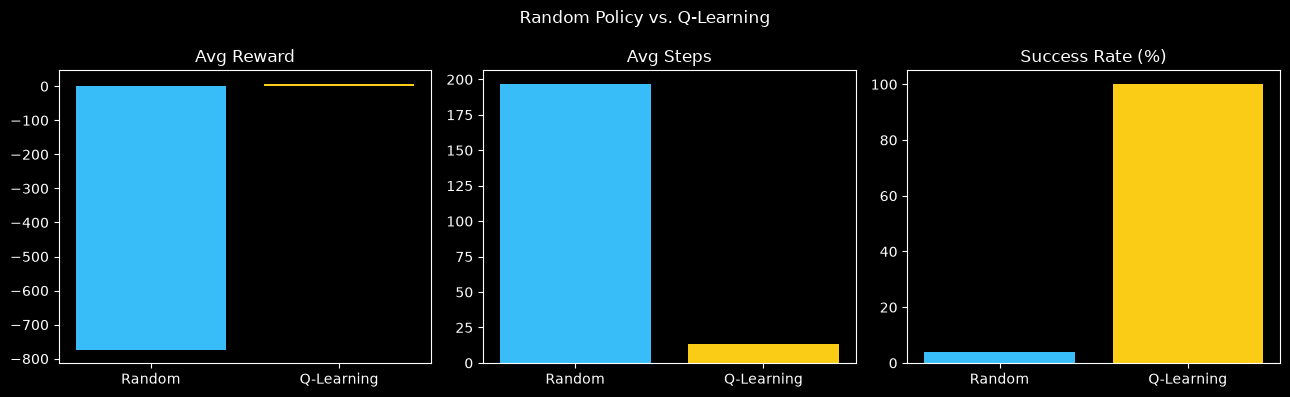

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
metrics = [("avg_reward", "Avg Reward"), ("avg_steps", "Avg Steps"), ("success_rate", "Success Rate")]
for ax, (key, label) in zip(axes, metrics):
    values = [random_eval[key], q_eval[key]]
    if key == "success_rate":
        values = [v * 100 for v in values]
        label += " (%)"
    ax.bar(["Random", "Q-Learning"], values, color=["#38bdf8", "#facc15"])
    ax.set_title(label)
plt.suptitle("Random Policy vs. Q-Learning")
plt.tight_layout()
plt.show()

## 16. Failure Analysis

Episodes where the agent did **not** deliver the passenger successfully (hit `max_steps`)
or scored a very low reward. Even a well-trained agent can occasionally fail on rare states
that were undersampled during training.

In [17]:
failures = [
    {"episode": i, "reward": r, "steps": s}
    for i, (r, s, success) in enumerate(zip(q_eval["rewards"], q_eval["steps"], q_eval["successes"]))
    if not success or r < 0
]
failures_df = pd.DataFrame(failures)
print(f"Number of failure episodes out of 100: {len(failures)}")
failures_df

Number of failure episodes out of 100: 0


""


## 17. Example Episode (Trained Agent)

Run one episode with the trained, greedy policy and print every step.

In [18]:
state, _ = env.reset(seed=7)
total_reward = 0.0
for step in range(max_steps):
    action = q_policy(state)
    next_state, reward, terminated, truncated, _ = env.step(action)
    total_reward += reward
    print(f"Step {step+1:2d} | action={ACTION_NAMES[action]:8s} | reward={reward:+.0f} | cumulative={total_reward:+.0f}")
    state = next_state
    if terminated or truncated:
        print("\nEpisode finished:", "SUCCESS" if terminated and not truncated else "TIMEOUT")
        break

Step  1 | action=South    | reward=-1 | cumulative=-1
Step  2 | action=Pickup   | reward=-1 | cumulative=-2
Step  3 | action=North    | reward=-1 | cumulative=-3
Step  4 | action=North    | reward=-1 | cumulative=-4
Step  5 | action=East     | reward=-1 | cumulative=-5
Step  6 | action=East     | reward=-1 | cumulative=-6
Step  7 | action=East     | reward=-1 | cumulative=-7
Step  8 | action=East     | reward=-1 | cumulative=-8
Step  9 | action=North    | reward=-1 | cumulative=-9
Step 10 | action=North    | reward=-1 | cumulative=-10
Step 11 | action=Drop-off | reward=+20 | cumulative=+10

Episode finished: SUCCESS


## 18. Conclusion

Starting from a Q-table of all zeros, a tabular Q-learning agent trained for 10,000 episodes
on Taxi-v3 learns to reliably solve the pickup-and-dropoff task in far fewer steps than a
random policy, with a much higher success rate. Key takeaways:

- **Q-learning** works by iteratively refining value estimates using the Bellman equation,
  bootstrapping off its own current knowledge (`max_a' Q(s', a')`).
- **Epsilon-greedy** exploration is essential early in training so the agent experiences
  enough of the state space before committing to a policy.
- Because Taxi-v3's state space is small and discrete, a simple lookup table is enough —
  no neural network required. Larger or continuous state spaces would need function
  approximation (e.g., Deep Q-Networks).
- The random-policy baseline makes it obvious *how much* the agent actually learned: it
  goes from ~2% success and deeply negative reward to 100% success and positive reward.
